# 使用盲卷积稀疏编码（BCSC）提取点击多径结构

目标记录：`010 | Voyage_Ori_01 / PulseTrain_014 / Click_008`

本 Notebook 将单个观测点击建模为

$$y = d * x + \varepsilon,$$

其中 $d$ 是未知的短时点击原子，$x$ 是稀疏的有符号到达序列。算法交替执行：

1. 固定原子 $d$，用 FISTA 求解带 $\ell_1$ 正则的卷积稀疏编码；
2. 固定稀疏编码 $x$，用投影梯度更新原子，并施加零均值、单位范数和符号约束；
3. 从稀疏编码的局部峰值读取各条传播路径的相对延迟和相对幅度。

> 说明：对单条波形进行盲分解存在尺度、符号和时移不唯一性。本实现用单位范数、固定原子支撑长度及原子主峰居中消除主要歧义；结果应理解为数据驱动的多径候选结构。

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, fftconvolve, correlate, find_peaks, windows

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None):
        print(desc or "处理中……")
        return iterable

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.unicode_minus"] = False

PROJECT_ROOT = Path(r"D:\Project_Github\Indo-Pacific-humpback-dolphin")
INPUT_WAV = PROJECT_ROOT / r"00_Data\Positive_Clicks_3500\Voyage_Ori_01\PulseTrain_014\Click_008\Pulse_008.wav"
OUTPUT_DIR = PROJECT_ROOT / r"18_多径提取算法\BCSC_010_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 默认方案参数
LOWCUT_HZ = 20_000.0
HIGHCUT_HZ = 190_000.0
ATOM_DURATION_MS = 0.25
OUTER_ITERATIONS = 35
FISTA_ITERATIONS = 120
DICTIONARY_ITERATIONS = 30
LAMBDA_RATIO = 0.075
MIN_PATH_DISTANCE_MS = 0.035
PEAK_RATIO = 0.015  # 候选展示阈值；相对于最大稀疏系数
RANDOM_SEED = 20260812

print(f"输入：{INPUT_WAV}")
print(f"输出：{OUTPUT_DIR}")


输入：D:\Project_Github\Indo-Pacific-humpback-dolphin\00_Data\Positive_Clicks_3500\Voyage_Ori_01\PulseTrain_014\Click_008\Pulse_008.wav
输出：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_results


## 1. 读取和预处理

读取完整 10 ms 点击片段，转换为浮点数，去直流并进行 20–190 kHz 零相位 Butterworth 带通滤波。边缘仅用 Tukey 窗轻微渐消，避免卷积模型把截断边界学习成原子。

采样率：576,000 Hz
样本数：5,761（10.002 ms）
原子长度：145 点（0.252 ms）


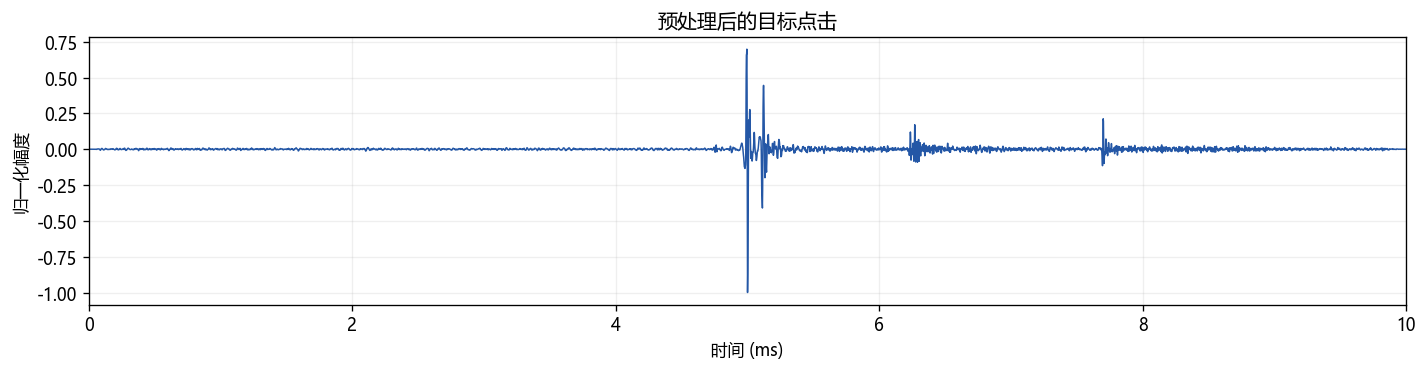

In [2]:
def to_float_audio(data):
    if np.issubdtype(data.dtype, np.integer):
        info = np.iinfo(data.dtype)
        scale = max(abs(info.min), info.max)
        return data.astype(np.float64) / scale
    return data.astype(np.float64)


def preprocess_click(path, lowcut_hz=20_000.0, highcut_hz=190_000.0):
    sample_rate, raw = wavfile.read(path)
    raw = to_float_audio(raw)
    if raw.ndim == 2:
        raw = raw.mean(axis=1)
    raw = raw - np.mean(raw)

    nyquist = sample_rate / 2.0
    if not (0 < lowcut_hz < highcut_hz < nyquist):
        raise ValueError(f"带通范围必须位于 (0, {nyquist:g}) Hz 内。")
    sos = butter(5, [lowcut_hz / nyquist, highcut_hz / nyquist], btype="bandpass", output="sos")
    filtered = sosfiltfilt(sos, raw)
    filtered *= windows.tukey(len(filtered), alpha=0.04)
    scale = np.max(np.abs(filtered)) + np.finfo(float).eps
    return sample_rate, raw, filtered / scale, scale


fs, raw, y, physical_scale = preprocess_click(INPUT_WAV, LOWCUT_HZ, HIGHCUT_HZ)
t_ms = np.arange(len(y)) / fs * 1e3
atom_len = int(round(ATOM_DURATION_MS * 1e-3 * fs))
atom_len += atom_len % 2 == 0  # 使用奇数长度，使原子有明确中心
code_len = len(y) - atom_len + 1

print(f"采样率：{fs:,} Hz")
print(f"样本数：{len(y):,}（{len(y) / fs * 1e3:.3f} ms）")
print(f"原子长度：{atom_len} 点（{atom_len / fs * 1e3:.3f} ms）")

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t_ms, y, lw=0.9, color="#2457A6")
ax.set(title="预处理后的目标点击", xlabel="时间 (ms)", ylabel="归一化幅度", xlim=(t_ms[0], t_ms[-1]))
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 2. BCSC 优化器

稀疏编码子问题为

$$\min_x \frac{1}{2}\lVert y-d*x\rVert_2^2+\lambda\lVert x\rVert_1,$$

使用 FISTA 求解。字典子问题固定 $x$ 后最小化重构误差，每步将原子投影回零均值单位球面。外层循环显示总体进度。

In [3]:
def soft_threshold(z, threshold):
    return np.sign(z) * np.maximum(np.abs(z) - threshold, 0.0)


def reconstruct(atom, activation, signal_len):
    return fftconvolve(activation, atom, mode="full")[:signal_len]


def adjoint_atom(residual, atom, activation_len):
    return correlate(residual, atom, mode="valid", method="fft")[:activation_len]


def adjoint_code(residual, activation, atom_length):
    return correlate(residual, activation, mode="valid", method="fft")[:atom_length]


def spectral_lipschitz(kernel, output_len):
    n_fft = 1 << int(np.ceil(np.log2(output_len)))
    return float(np.max(np.abs(np.fft.rfft(kernel, n=n_fft)) ** 2) + 1e-10)


def normalize_atom(atom):
    atom = np.asarray(atom, dtype=float)
    atom = atom - np.mean(atom)
    norm = np.linalg.norm(atom)
    if norm < 1e-12:
        raise RuntimeError("原子范数接近 0，无法继续优化。")
    atom = atom / norm
    # 固定符号歧义：原子绝对主峰为正。
    if atom[np.argmax(np.abs(atom))] < 0:
        atom = -atom
    return atom


def initialize_atom(signal, atom_length):
    peak = int(np.argmax(np.abs(signal)))
    half = atom_length // 2
    padded = np.pad(signal, (half, half))
    atom = padded[peak:peak + atom_length].copy()
    atom *= windows.tukey(atom_length, alpha=0.35)
    return normalize_atom(atom)


def fista_sparse_code(signal, atom, lam, x0=None, n_iter=120):
    activation_len = len(signal) - len(atom) + 1
    x = np.zeros(activation_len) if x0 is None else x0.copy()
    z = x.copy()
    momentum = 1.0
    lipschitz = spectral_lipschitz(atom, len(signal))

    for _ in range(n_iter):
        residual = reconstruct(atom, z, len(signal)) - signal
        gradient = adjoint_atom(residual, atom, activation_len)
        x_new = soft_threshold(z - gradient / lipschitz, lam / lipschitz)
        momentum_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * momentum * momentum))
        z = x_new + ((momentum - 1.0) / momentum_new) * (x_new - x)
        x, momentum = x_new, momentum_new
    return x


def update_atom(signal, activation, atom, n_iter=30):
    if np.linalg.norm(activation) < 1e-12:
        return atom
    lipschitz = spectral_lipschitz(activation, len(signal))
    step = 0.8 / lipschitz
    updated = atom.copy()
    taper = windows.tukey(len(atom), alpha=0.20)
    for _ in range(n_iter):
        residual = reconstruct(updated, activation, len(signal)) - signal
        gradient = adjoint_code(residual, activation, len(atom))
        updated = normalize_atom((updated - step * gradient) * taper)
    return updated


def shift_atom_and_code(atom, activation):
    # 把原子绝对主峰移至中心，并反向平移编码以保持到达时刻。
    center = len(atom) // 2
    shift = center - int(np.argmax(np.abs(atom)))
    shifted_atom = np.roll(atom, shift)
    if shift > 0:
        shifted_atom[:shift] = 0.0
    elif shift < 0:
        shifted_atom[shift:] = 0.0
    shifted_atom = normalize_atom(shifted_atom)

    shifted_code = np.roll(activation, -shift)
    if shift > 0:
        shifted_code[-shift:] = 0.0
    elif shift < 0:
        shifted_code[:-shift] = 0.0
    return shifted_atom, shifted_code


def bcsc(signal, atom_length, outer_iterations=35, fista_iterations=120, dictionary_iterations=30,
         lambda_ratio=0.075):
    atom = initialize_atom(signal, atom_length)
    activation = np.zeros(len(signal) - atom_length + 1)
    history = []

    for iteration in tqdm(range(outer_iterations), total=outer_iterations, desc="BCSC 总体进度"):
        max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
        # 前几轮由较强稀疏约束逐渐退火到目标 lambda，降低坏局部极值风险。
        anneal = 1.8 - 0.8 * min(iteration / max(outer_iterations - 1, 1), 1.0)
        lam = lambda_ratio * anneal * max_corr
        activation = fista_sparse_code(signal, atom, lam, activation, fista_iterations)
        atom = update_atom(signal, activation, atom, dictionary_iterations)
        atom, activation = shift_atom_and_code(atom, activation)

        estimate = reconstruct(atom, activation, len(signal))
        residual = signal - estimate
        objective = 0.5 * np.dot(residual, residual) + lam * np.sum(np.abs(activation))
        explained = 1.0 - np.dot(residual, residual) / (np.dot(signal, signal) + 1e-12)
        history.append((iteration + 1, objective, explained, lam, np.count_nonzero(np.abs(activation) > 1e-8)))

    # 最后用目标 lambda 再精炼一次稀疏编码。
    max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
    lam = lambda_ratio * max_corr
    activation = fista_sparse_code(signal, atom, lam, activation, 2 * fista_iterations)
    estimate = reconstruct(atom, activation, len(signal))
    return atom, activation, estimate, np.asarray(history)


## 3. 运行盲卷积稀疏编码

这一单元是主要计算步骤。进度条的 0–100% 对应全部外层交替优化迭代。

BCSC 总体进度:   0%|          | 0/35 [00:00<?, ?it/s]

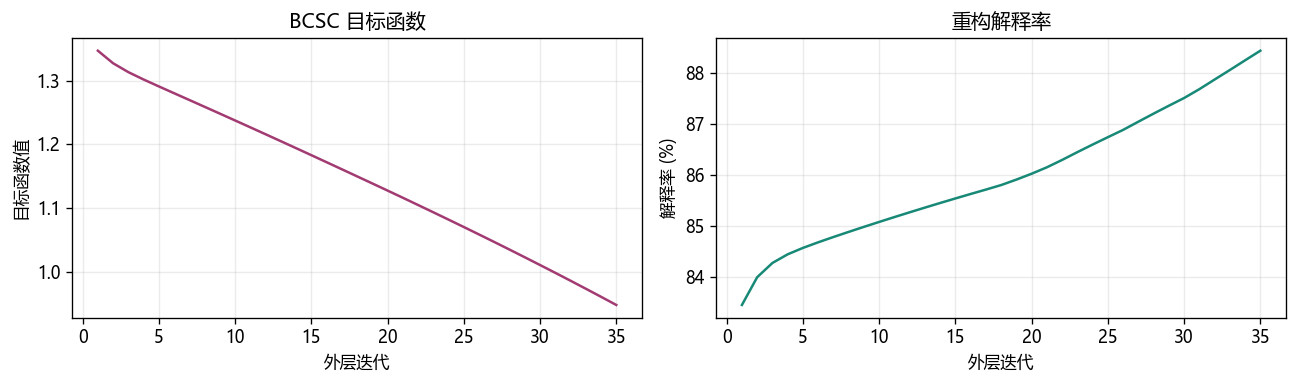

最终重构解释率：88.47%


In [4]:
np.random.seed(RANDOM_SEED)
atom, activation, reconstruction, history = bcsc(
    y,
    atom_length=atom_len,
    outer_iterations=OUTER_ITERATIONS,
    fista_iterations=FISTA_ITERATIONS,
    dictionary_iterations=DICTIONARY_ITERATIONS,
    lambda_ratio=LAMBDA_RATIO,
)
residual = y - reconstruction
explained_variance = 1.0 - np.sum(residual ** 2) / (np.sum(y ** 2) + 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(history[:, 0], history[:, 1], color="#A23B72", lw=1.5)
axes[0].set(title="BCSC 目标函数", xlabel="外层迭代", ylabel="目标函数值")
axes[1].plot(history[:, 0], history[:, 2] * 100, color="#188977", lw=1.5)
axes[1].set(title="重构解释率", xlabel="外层迭代", ylabel="解释率 (%)")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"最终重构解释率：{explained_variance * 100:.2f}%")


## 4. 从稀疏编码提取多径候选

编码系数的位置表示学习原子的起点。为获得原子的物理到达时刻，加上原子中心偏移。候选展示阈值是最大系数的 1.5%，相邻候选至少间隔 0.035 ms；最早的显著候选定义为直达径，其余为多径。较低阈值用于保留弱后续到达，最终解释时应同时参考稀疏系数、重构残差和物理场景。

In [5]:
def extract_paths(activation, sample_rate, atom_length, peak_ratio=0.015, min_distance_ms=0.035):
    magnitude = np.abs(activation)
    if magnitude.max() <= 0:
        raise RuntimeError("稀疏编码中没有非零激活，无法提取路径。")
    min_distance = max(1, int(round(min_distance_ms * 1e-3 * sample_rate)))
    peaks, props = find_peaks(magnitude, height=peak_ratio * magnitude.max(), distance=min_distance)
    if not len(peaks):
        peaks = np.array([int(np.argmax(magnitude))])

    # 防止全局最大值恰位于编码边界而被 find_peaks 忽略。
    global_peak = int(np.argmax(magnitude))
    if global_peak not in peaks and magnitude[global_peak] >= peak_ratio * magnitude.max():
        peaks = np.sort(np.append(peaks, global_peak))

    arrival_samples = peaks + atom_length // 2
    order = np.argsort(arrival_samples)
    peaks, arrival_samples = peaks[order], arrival_samples[order]
    coeff = activation[peaks]
    delay_ms = (arrival_samples - arrival_samples[0]) / sample_rate * 1e3
    relative_amplitude = np.abs(coeff) / (np.abs(coeff[0]) + 1e-12)
    relative_db = 20 * np.log10(relative_amplitude + 1e-12)

    return [
        {
            "path": "direct" if i == 0 else f"multipath_{i}",
            "arrival_sample": int(sample),
            "arrival_time_ms": float(sample / sample_rate * 1e3),
            "relative_delay_ms": float(delay_ms[i]),
            "signed_coefficient": float(coeff[i]),
            "relative_amplitude": float(relative_amplitude[i]),
            "relative_level_db": float(relative_db[i]),
        }
        for i, sample in enumerate(arrival_samples)
    ], peaks


paths, path_peaks = extract_paths(
    activation, fs, atom_len, peak_ratio=PEAK_RATIO, min_distance_ms=MIN_PATH_DISTANCE_MS
)

print(f"检测到 {len(paths)} 条显著路径：")
print(f"{'路径':<14}{'到达时刻/ms':>14}{'相对延迟/ms':>14}{'相对幅度':>12}{'相对级/dB':>12}")
for p in paths:
    print(
        f"{p['path']:<14}{p['arrival_time_ms']:>14.4f}{p['relative_delay_ms']:>14.4f}"
        f"{p['relative_amplitude']:>12.3f}{p['relative_level_db']:>12.2f}"
    )

with (OUTPUT_DIR / "bcsc_paths.json").open("w", encoding="utf-8") as f:
    json.dump(
        {
            "record": "010 | Voyage_Ori_01 / PulseTrain_014 / Click_008",
            "input_wav": str(INPUT_WAV),
            "sample_rate_hz": fs,
            "atom_duration_ms": atom_len / fs * 1e3,
            "explained_variance": float(explained_variance),
            "paths": paths,
        },
        f,
        ensure_ascii=False,
        indent=2,
    )


检测到 5 条显著路径：
路径                   到达时刻/ms       相对延迟/ms        相对幅度      相对级/dB
direct                5.0000        0.0000       1.000        0.00
multipath_1           5.1181        0.1181       0.295      -10.62
multipath_2           5.2361        0.2361       0.026      -31.65
multipath_3           6.2691        1.2691       0.018      -34.68
multipath_4           7.6997        2.6997       0.061      -24.35


## 5. 结果图

综合图依次展示原始/重构波形、学习到的点击原子、稀疏到达序列、多径相对延迟和残差。图和数值结果会同时保存到 `BCSC_010_results`。

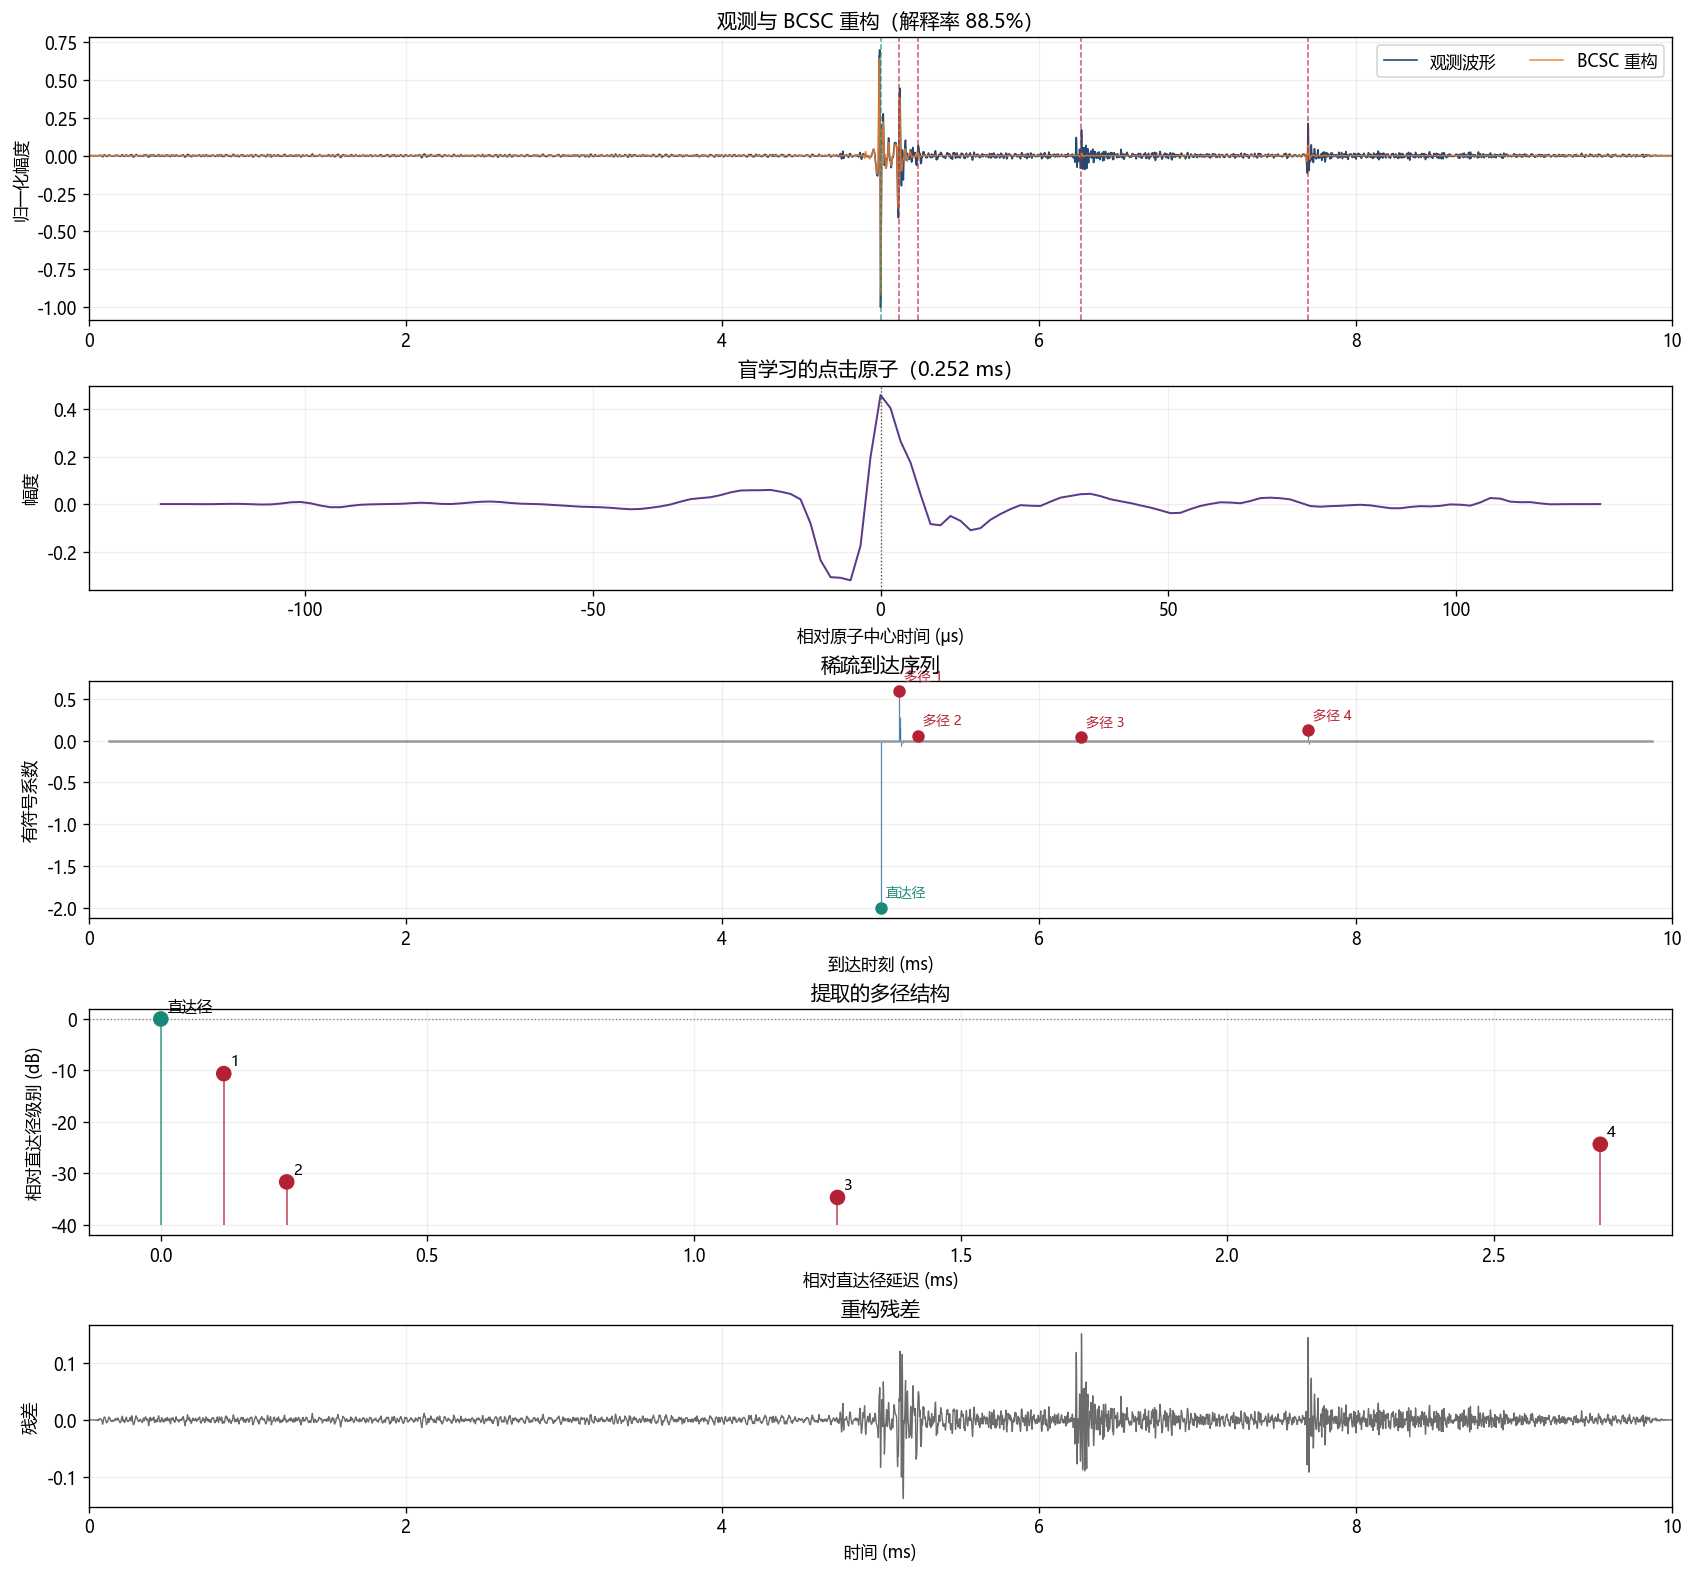

结果图已保存：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_results\bcsc_multipath_structure.png


In [6]:
arrival_samples = np.array([p["arrival_sample"] for p in paths])
arrival_times_ms = arrival_samples / fs * 1e3
atom_time_us = (np.arange(atom_len) - atom_len // 2) / fs * 1e6
code_time_ms = (np.arange(code_len) + atom_len // 2) / fs * 1e3

fig = plt.figure(figsize=(14, 13), constrained_layout=True)
grid = fig.add_gridspec(5, 1, height_ratios=[1.25, 0.9, 1.05, 1.0, 0.8])

ax1 = fig.add_subplot(grid[0])
ax1.plot(t_ms, y, color="#244A73", lw=1.0, label="观测波形")
ax1.plot(t_ms, reconstruction, color="#E07A2D", lw=0.9, alpha=0.9, label="BCSC 重构")
for i, x_ms in enumerate(arrival_times_ms):
    ax1.axvline(x_ms, color="#B32134" if i else "#188977", ls="--", lw=0.9, alpha=0.75)
ax1.set(title=f"观测与 BCSC 重构（解释率 {explained_variance * 100:.1f}%）", ylabel="归一化幅度", xlim=(t_ms[0], t_ms[-1]))
ax1.legend(loc="upper right", ncol=2)

ax2 = fig.add_subplot(grid[1])
ax2.plot(atom_time_us, atom, color="#5B3A8C", lw=1.2)
ax2.axvline(0, color="0.3", ls=":", lw=0.8)
ax2.set(title=f"盲学习的点击原子（{atom_len / fs * 1e3:.3f} ms）", xlabel="相对原子中心时间 (μs)", ylabel="幅度")

ax3 = fig.add_subplot(grid[2])
markerline, stemlines, baseline = ax3.stem(code_time_ms, activation, linefmt="#2E6E9E", markerfmt=" ", basefmt="0.6")
plt.setp(stemlines, linewidth=0.75, alpha=0.8)
for i, peak in enumerate(path_peaks):
    color = "#188977" if i == 0 else "#B32134"
    ax3.scatter(code_time_ms[peak], activation[peak], s=42, color=color, zorder=3)
    ax3.annotate("直达径" if i == 0 else f"多径 {i}", (code_time_ms[peak], activation[peak]),
                 xytext=(3, 7), textcoords="offset points", fontsize=8, color=color)
ax3.set(title="稀疏到达序列", xlabel="到达时刻 (ms)", ylabel="有符号系数", xlim=(t_ms[0], t_ms[-1]))

ax4 = fig.add_subplot(grid[3])
delay = np.array([p["relative_delay_ms"] for p in paths])
level = np.array([p["relative_level_db"] for p in paths])
colors = ["#188977"] + ["#B32134"] * (len(paths) - 1)
ax4.scatter(delay, level, s=70, c=colors, zorder=3)
for i, (xx, yy) in enumerate(zip(delay, level)):
    ax4.vlines(xx, min(-40, level.min() - 3), yy, color=colors[i], lw=1.2, alpha=0.65)
    ax4.annotate("直达径" if i == 0 else str(i), (xx, yy), xytext=(4, 5), textcoords="offset points", fontsize=9)
ax4.axhline(0, color="0.5", ls=":", lw=0.8)
ax4.set(title="提取的多径结构", xlabel="相对直达径延迟 (ms)", ylabel="相对直达径级别 (dB)")

ax5 = fig.add_subplot(grid[4])
ax5.plot(t_ms, residual, color="#6B6B6B", lw=0.8)
ax5.set(title="重构残差", xlabel="时间 (ms)", ylabel="残差", xlim=(t_ms[0], t_ms[-1]))

for ax in (ax1, ax2, ax3, ax4, ax5):
    ax.grid(alpha=0.2)

figure_path = OUTPUT_DIR / "bcsc_multipath_structure.png"
fig.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()
print(f"结果图已保存：{figure_path}")


## 6. 单独导出便于引用的多径结构图

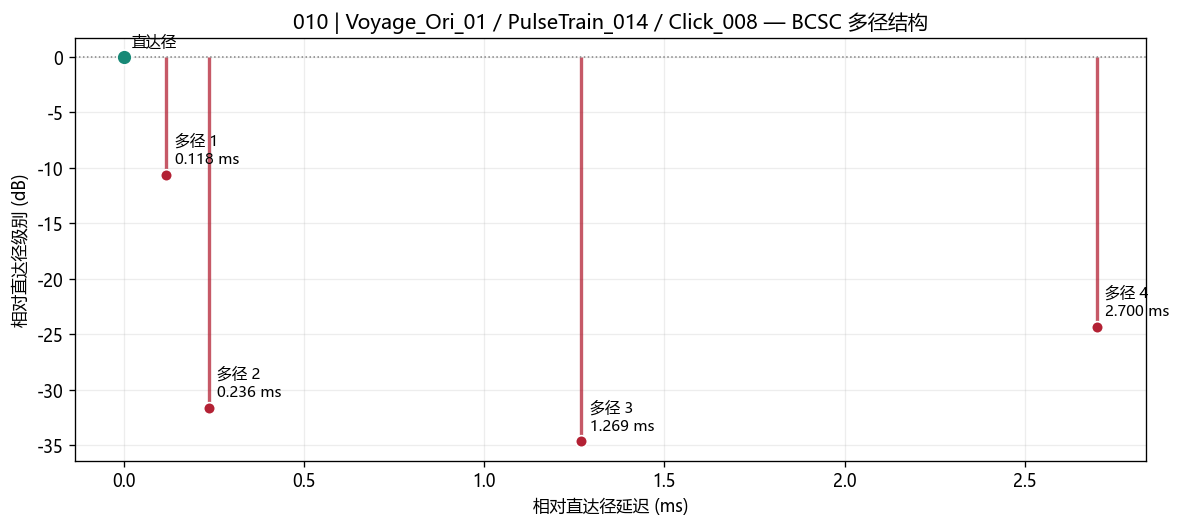

多径结构图已保存：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_results\bcsc_path_delays.png


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
markerline, stemlines, baseline = ax.stem(delay, level, linefmt="#B32134", markerfmt="o", basefmt=" ")
plt.setp(markerline, markersize=7, markerfacecolor="#B32134", markeredgecolor="white")
plt.setp(stemlines, linewidth=2, alpha=0.75)
if len(paths):
    ax.scatter(delay[0], level[0], s=80, color="#188977", edgecolor="white", zorder=4)
for i, p in enumerate(paths):
    label = "直达径" if i == 0 else f"多径 {i}\n{p['relative_delay_ms']:.3f} ms"
    ax.annotate(label, (delay[i], level[i]), xytext=(5, 7), textcoords="offset points", fontsize=9)
ax.axhline(0, color="0.5", ls=":", lw=0.9)
ax.set(title="010 | Voyage_Ori_01 / PulseTrain_014 / Click_008 — BCSC 多径结构",
       xlabel="相对直达径延迟 (ms)", ylabel="相对直达径级别 (dB)")
ax.grid(alpha=0.22)
plt.tight_layout()
structure_path = OUTPUT_DIR / "bcsc_path_delays.png"
fig.savefig(structure_path, dpi=220, bbox_inches="tight")
plt.show()
print(f"多径结构图已保存：{structure_path}")


## 7. 估计的原始 click 信号

这里分别给出两种表示：

1. **单位范数原子 $d$**：表示 BCSC 从观测波形中盲学习到的、去除多径后的 click 形状；适合比较波形和频谱形态。
2. **直达径波形 $a_0d$**：将原子乘以直达径的有符号稀疏系数 $a_0$，保留模型估计的幅度与极性。由于预处理阶段曾将滤波波形归一化，再乘 `physical_scale` 可恢复到 WAV 浮点满量程尺度。

注意：该结果是模型分解得到的源波形估计，并非独立测得的真实发声源波形。

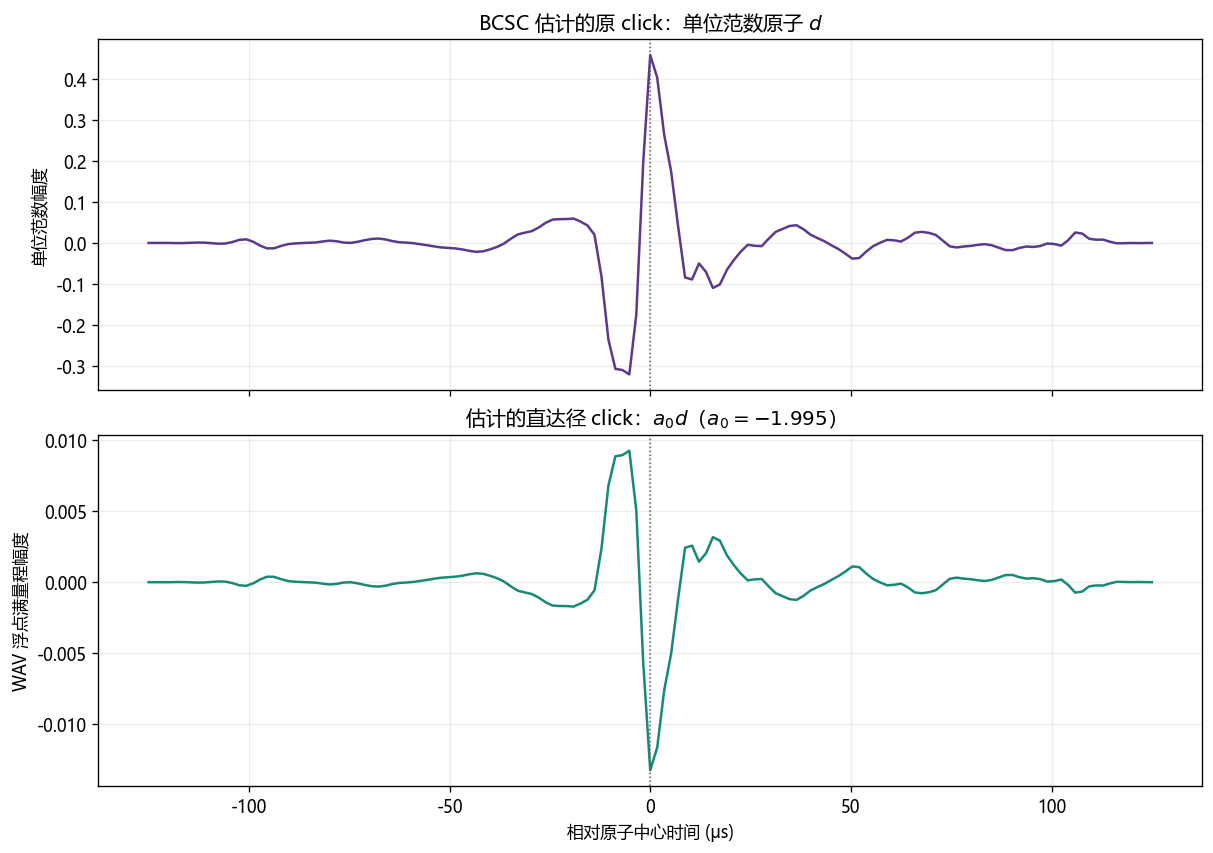

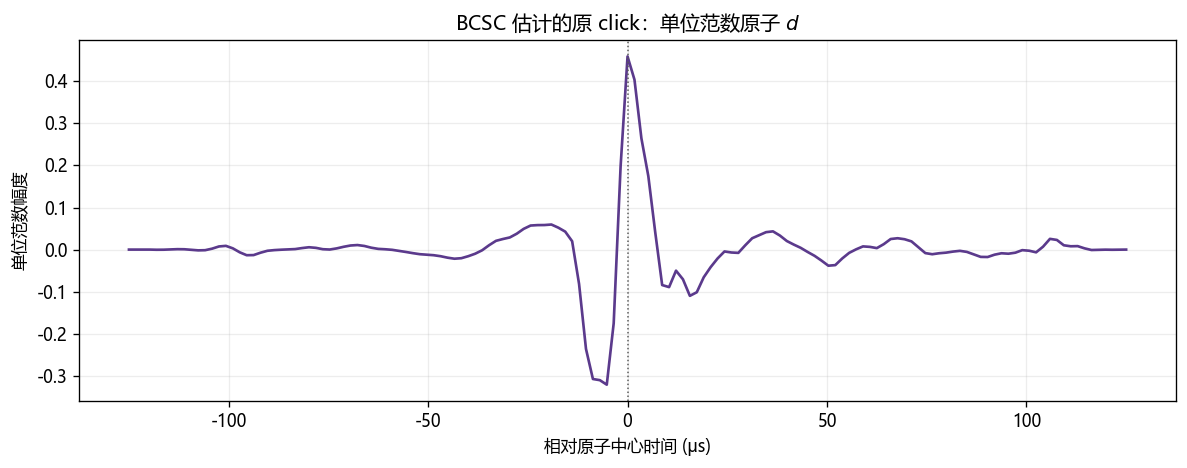

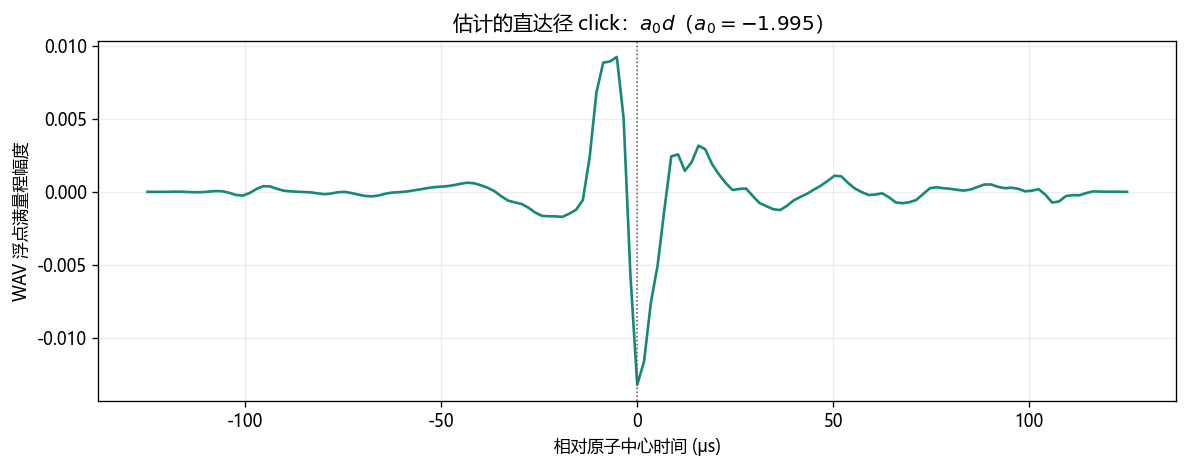

对比图：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_results\estimated_original_click_comparison.png
单位范数原子：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_results\estimated_unit_norm_atom.png
直达径 click：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_results\estimated_direct_arrival_click.png


In [8]:
direct_coefficient = paths[0]["signed_coefficient"]
unit_atom = atom.copy()
direct_click_normalized = direct_coefficient * atom
direct_click_wav_scale = physical_scale * direct_click_normalized

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)

axes[0].plot(atom_time_us, unit_atom, color="#5B3A8C", lw=1.5)
axes[0].axvline(0, color="0.35", ls=":", lw=0.9)
axes[0].set(
    title="BCSC 估计的原 click：单位范数原子 $d$",
    ylabel="单位范数幅度",
)

axes[1].plot(atom_time_us, direct_click_wav_scale, color="#188977", lw=1.5)
axes[1].axvline(0, color="0.35", ls=":", lw=0.9)
axes[1].set(
    title=rf"估计的直达径 click：$a_0d$（$a_0={direct_coefficient:.3f}$）",
    xlabel="相对原子中心时间 (μs)",
    ylabel="WAV 浮点满量程幅度",
)

for ax in axes:
    ax.grid(alpha=0.22)

comparison_path = OUTPUT_DIR / "estimated_original_click_comparison.png"
fig.savefig(comparison_path, dpi=220, bbox_inches="tight")
plt.show()

for waveform, title, ylabel, filename, color in (
    (unit_atom, "BCSC 估计的原 click：单位范数原子 $d$", "单位范数幅度",
     "estimated_unit_norm_atom.png", "#5B3A8C"),
    (direct_click_wav_scale, rf"估计的直达径 click：$a_0d$（$a_0={direct_coefficient:.3f}$）",
     "WAV 浮点满量程幅度", "estimated_direct_arrival_click.png", "#188977"),
):
    fig_single, ax = plt.subplots(figsize=(10, 4))
    ax.plot(atom_time_us, waveform, color=color, lw=1.6)
    ax.axvline(0, color="0.35", ls=":", lw=0.9)
    ax.set(title=title, xlabel="相对原子中心时间 (μs)", ylabel=ylabel)
    ax.grid(alpha=0.22)
    fig_single.tight_layout()
    fig_single.savefig(OUTPUT_DIR / filename, dpi=220, bbox_inches="tight")
    plt.show()

print(f"对比图：{comparison_path}")
print(f"单位范数原子：{OUTPUT_DIR / 'estimated_unit_norm_atom.png'}")
print(f"直达径 click：{OUTPUT_DIR / 'estimated_direct_arrival_click.png'}")
